# LayingRate_Model.ipynb
**ICS 3202 — Artificial Intelligence | Project Deliverable 2**

**Goal:** forecast a flock's laying rate (% of hens laying per day) **1, 4 and 8 weeks ahead**, so the ERP can warn the farmer early.

**Model:** a **random forest**, tested on flocks it has never seen.

## 1. Inputs and answer

For every week of every flock, the model gets what the farmer knows that week and must predict the laying rate some weeks later.

| Inputs (13) | Answer |
|---|---|
| flock age, laying rate this week and the 2 weeks before, trend, feed per hen, mortality, breed standard | laying rate 1, 4 or 8 weeks later |

In [1]:
# In Colab, fetch the project first (the data file and the ml_engine code)
import os
if not os.path.exists('ml_engine'):
    !git clone -q https://github.com/alfredmuriu/SemProject_MLEngine.git
    %cd SemProject_MLEngine

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ml_engine.data import FEATURES, HORIZONS, load_raw, standard_curve, to_flocks, training_table

raw = load_raw()
flocks = to_flocks(raw)              # cleaned weekly records, one list per flock
curve = standard_curve(raw)          # the breed's target laying rate by age
tables = {h: training_table(flocks, h, curve) for h in HORIZONS}

for h, t in tables.items():
    print(f"{h} week(s) ahead: {len(t)} examples")
tables[4][['flock_id'] + FEATURES[:5] + ['target']].head()

1 week(s) ahead: 439 examples
4 week(s) ahead: 412 examples
8 week(s) ahead: 376 examples


,flock_id,age_weeks,lay_rate,lay_rate_1,lay_rate_2,trend,target
0,G1-F1,22,1.365818,0.156884,0.036914,1.328904,57.780447
1,G1-F1,23,5.592470,1.365818,0.156884,5.435585,69.996304
2,G1-F1,24,17.201920,5.592470,1.365818,15.836102,83.236246
3,G1-F1,25,35.571152,17.201920,5.592470,29.978682,88.164586
4,G1-F1,26,57.780447,35.571152,17.201920,40.578528,87.924179


## 2. Train and test the random forest

To test fairly, the model is trained on 8 flocks and tested on the 9th, repeated for all 9 flocks.
Its forecasts are compared with simple rules a farmer could use without a model.

In [2]:
from sklearn.ensemble import RandomForestRegressor
from ml_engine.model import BASELINES, leave_one_flock_out, score

def random_forest():
    return RandomForestRegressor(n_estimators=400, min_samples_leaf=3, random_state=42, n_jobs=-1)

scores, forecasts = {}, {}
for h, t in tables.items():
    forecasts[h] = leave_one_flock_out(random_forest, t)
    scores[h] = {'Random forest': score(t['target'], forecasts[h])}
    for name, rule in BASELINES.items():
        scores[h][name] = score(t['target'], rule(t))

errors = pd.DataFrame({f'{h} wk ahead': {m: s['mae'] for m, s in scores[h].items()} for h in HORIZONS})
print('Average error on unseen flocks (laying-rate points, lower is better)')
errors.round(2)

Average error on unseen flocks (laying-rate points, lower is better)


,1 wk ahead,4 wk ahead,8 wk ahead
Random forest,2.50,2.83,2.91
Same as this week,3.50,6.89,8.38
Breed standard,5.36,3.44,3.14
Standard + this week's gap,3.06,5.73,6.66


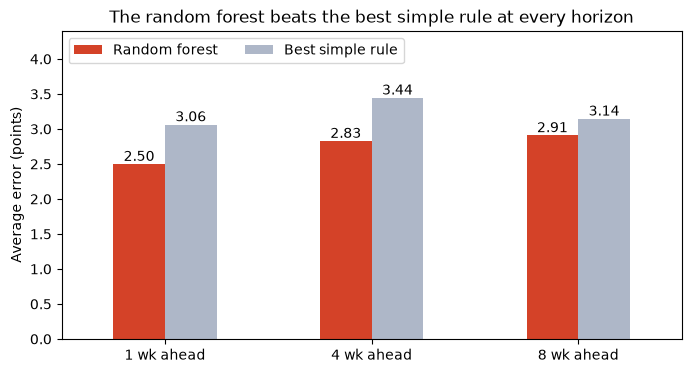

In [3]:
best_rule = errors.drop('Random forest').min()
chart = pd.DataFrame({'Random forest': errors.loc['Random forest'], 'Best simple rule': best_rule})
ax = chart.plot.bar(rot=0, figsize=(8, 4), color=['#d44228', '#aeb7c8'])
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f')
ax.set_ylim(0, 4.4); ax.legend(loc='upper left', ncol=2)
ax.set_ylabel('Average error (points)')
ax.set_title('The random forest beats the best simple rule at every horizon')
plt.show()

The random forest is about **2.5 points** off one week ahead and under 3 points two months ahead.
That is better than every simple rule, by about 18% at 1 and 4 weeks.

## 3. Did it really learn?

If the model is learning patterns that carry across flocks, its error on a new flock should fall as it trains on more flocks.

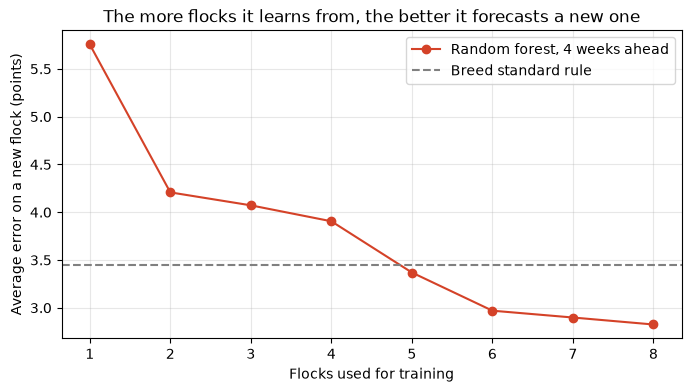

In [4]:
t = tables[4]
ids = sorted(t['flock_id'].unique())
rng = np.random.default_rng(0)
curve_points = []
for k in range(1, 9):
    errs = []
    for test_flock in ids:
        others = [f for f in ids if f != test_flock]
        train = t[t['flock_id'].isin(rng.choice(others, size=k, replace=False))]
        test = t[t['flock_id'] == test_flock]
        fitted = random_forest().fit(train[FEATURES], train['target'])
        errs.append(np.abs(test['target'] - fitted.predict(test[FEATURES])).mean())
    curve_points.append(np.mean(errs))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 9), curve_points, 'o-', color='#d44228', label='Random forest, 4 weeks ahead')
plt.axhline(errors.loc['Breed standard', '4 wk ahead'], color='grey', linestyle='--', label='Breed standard rule')
plt.xlabel('Flocks used for training'); plt.ylabel('Average error on a new flock (points)')
plt.title('The more flocks it learns from, the better it forecasts a new one')
plt.legend(); plt.grid(alpha=0.3); plt.show()

Its error falls steadily as it sees more flocks, so it is learning, not memorising.

## 4. One flock it never saw, forecast week by week

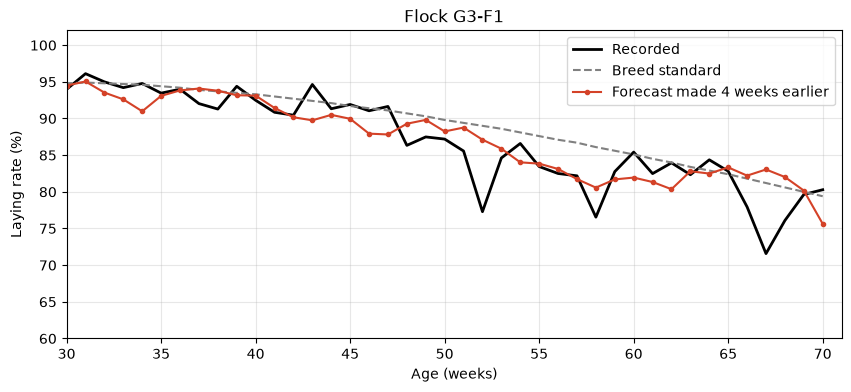

In [5]:
flock = 'G3-F1'
t1, t4 = tables[1], tables[4]
plt.figure(figsize=(10, 4))
plt.plot(t1.loc[t1.flock_id == flock, 'target_age_weeks'], t1.loc[t1.flock_id == flock, 'target'], 'k', linewidth=2, label='Recorded')
plt.plot(list(curve), list(curve.values()), '--', color='grey', label='Breed standard')
plt.plot(t4.loc[t4.flock_id == flock, 'target_age_weeks'], forecasts[4][(t4.flock_id == flock).to_numpy()],
         '.-', color='#d44228', label='Forecast made 4 weeks earlier')
plt.xlim(30, 71); plt.ylim(60, 102)
plt.xlabel('Age (weeks)'); plt.ylabel('Laying rate (%)'); plt.title(f'Flock {flock}')
plt.legend(); plt.grid(alpha=0.3); plt.show()

The forecasts follow the flock's own path rather than the breed standard. Sudden dips from disease or stress can't be foreseen from the records.

## 5. Train on all flocks and save

The final models are trained on all 9 flocks and saved for the web app (`models/flock_forecaster.joblib`).

In [6]:
from ml_engine.model import save

bundle = {'horizons': {}, 'standard_curve': curve, 'features': FEATURES,
          'n_flocks': len(flocks), 'n_weeks': sum(len(w) for w in flocks.values())}
for h, t in tables.items():
    final = random_forest().fit(t[FEATURES], t['target'])
    bundle['horizons'][h] = {'model': final, 'model_name': 'Random forest', 'results': scores[h], 'n_rows': len(t)}

os.makedirs('models', exist_ok=True)
save(bundle, 'models/flock_forecaster.joblib')
print('Saved models/flock_forecaster.joblib')

Saved models/flock_forecaster.joblib


## 6. How the ERP uses it — the agent

A **model-based reflex agent** turns the forecasts into advice for the farmer.

| Condition | Advice |
|---|---|
| laying more than 5 points below the breed standard | check feed, water, lighting and disease |
| on track now, but forecast more than 5 points below standard in 4 weeks | early warning: act before production drops |
| weekly deaths above 0.5% | inspect the flock, consider a vet |
| feed above 2 kg per dozen eggs | check for feed wastage |

It also predicts how many eggs to expect next week.

## 7. Limitations
- The data comes from one farm in Colombia (9 flocks), so the model should be retrained on Kenyan farm records before real use.
- Sudden drops from disease or heat stress are not in the records, so they can't be forecast in advance.